<div style="background:#080c10;padding:22px 26px;border-radius:10px;border-left:4px solid #00d4ff">
<h1 style="color:#00d4ff;margin:0 0 8px 0">International Football Odds — Verify before you buy</h1>
<p style="color:#e6edf3;margin:0;font-size:15px">Every figure of the listing, recomputed from the files of the full product:
11,118 matches, 28,943,376 timestamped quotes from 5 named bookmakers incl. Pinnacle, 661,507 snapshots from 37 more
bookmakers, 18 international competitions, 2016–2026.</p>
</div>

This notebook runs on the **full product**, not on the sample. Each section states a claim of the listing,
recomputes it from the files and prints **PASS** or **FAIL**. The expected values are written once, in plain
sight, in the `CLAIMS` cell; everything else is read from the data.

⚽ **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/hethzg?utm_source=github&utm_medium=notebook&utm_campaign=intl_premium&utm_content=notebook_top)** · free 20-match sample: same files, same columns.

## 0 · Setup

In [1]:
import os, glob, hashlib, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

def find_root():
    """Folder of the full product: the Intl_Matches.csv with the most rows wins (sample and full may both be attached)."""
    hits = []
    for base in (os.environ.get("INTL_ROOT", ""), "/kaggle/input", "."):
        if base and os.path.isdir(base):
            hits += glob.glob(os.path.join(base, "**", "Intl_Matches.csv"), recursive=True)
    if not hits:
        raise FileNotFoundError("Intl_Matches.csv not found: attach the dataset to this notebook")
    return os.path.dirname(max(hits, key=os.path.getsize))

ROOT = find_root()
print("Product folder:", ROOT)

def table_files(prefix):
    """The 18 per-competition files of a table, wherever they sit under the product folder:
    .csv.gz as shipped, or .csv when the hosting platform stores them decompressed."""
    for ext in (".csv.gz", ".csv"):
        # files only: Kaggle stores each decompressed .csv.gz as a folder "X.csv" that holds the file "X.csv"
        hits = sorted(p for p in glob.glob(os.path.join(ROOT, "**", prefix + "*" + ext), recursive=True)
                      if os.path.isfile(p))
        if hits:
            return hits
    return []

def stem(path):
    """File name without folder or extension: the key of the MANIFEST row counts."""
    b = os.path.basename(path)
    return b[:-7] if b.endswith(".csv.gz") else b.rsplit(".", 1)[0]

FILES = {t: table_files(p) for t, p in (("odds", "Intl_Odds_Timestamped_"), ("snapshots", "Intl_Bookmaker_Snapshots_"),
                                        ("events", "Intl_Events_"), ("lineups", "Intl_Lineups_"),
                                        ("minute_stats", "Intl_Minute_Stats_"))}
for t, fs in FILES.items():
    kinds = sorted({".csv.gz" if f.endswith(".gz") else ".csv" for f in fs}) or ["none found"]
    print(f"{t:13} {len(fs):>2} files  ({', '.join(kinds)})")
assert all(len(fs) == 18 for fs in FILES.values()), \
    "each table should have 18 files, one per competition: is the dataset fully processed on this platform?"

# Olivier Sports Data dark signature. HDA = home / draw / away, checked for colour-blind and normal-vision
# separation on this background.
BG, FG, FG2, GRID, CYAN = "#080c10", "#e6edf3", "#9aa7b2", "#1c2630", "#00d4ff"
HDA = {"Home": "#00a3cc", "Draw": "#c98500", "Away": "#d55181"}
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": FG2, "xtick.color": FG2, "ytick.color": FG2,
    "text.color": FG, "axes.titlecolor": FG, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10.5,
    "legend.frameon": False, "figure.dpi": 110,
})

RESULTS = []
def check(claim, ok, detail=""):
    RESULTS.append((claim, bool(ok), detail))
    print(("PASS  " if ok else "FAIL  ") + claim + (f"   [{detail}]" if detail else ""))

def epoch(s):
    """ISO 8601 UTC 'YYYY-MM-DDTHH:MM:SSZ' -> Unix seconds (NaN when empty)."""
    t = pd.to_datetime(s, format="%Y-%m-%dT%H:%M:%SZ", utc=True, errors="coerce")
    return (t - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds()

BOOKS = ["Bet365", "Pinnacle", "Unibet", "Betfair", "Betsson"]
ORDER = ["UEFA_CL", "UEFA_EL", "UEFA_ECL", "UEFA_NL", "EURO_2020", "EURO_2024", "WC_2018", "WC_2022", "WC_2026",
         "FIFA_CWC", "LIBERTA", "SUDAM", "COPA_AM", "CONCACAF", "AFC_CL", "AFC_ASIA", "CAF_CL", "CAF_AFCON"]

Product folder: /data/International_Football_Premium_2016-2026
odds          18 files  (.csv.gz)
snapshots     18 files  (.csv.gz)
events        18 files  (.csv.gz)
lineups       18 files  (.csv.gz)
minute_stats  18 files  (.csv.gz)


## 1 · The claims

Copied from the listing. Nothing below is adjusted to fit: if the files disagree, the cell prints FAIL.

In [2]:
CLAIMS = {
    "matches": 11_118, "club": 9_644, "national": 1_474,
    "competitions": 18, "confederations": 6, "editions": 110,
    "first_kickoff_on": "2016-08-31", "last_kickoff_before": "2026-10-01T00:00:00Z",
    "extra_time": 206, "penalty_shootouts": 270, "neutral_venue": 1_190,
    "matches_per_competition": {
        "UEFA_CL": 1_390, "UEFA_EL": 1_833, "UEFA_ECL": 729, "UEFA_NL": 712, "EURO_2020": 51, "EURO_2024": 51,
        "WC_2018": 64, "WC_2022": 64, "WC_2026": 104, "FIFA_CWC": 125, "LIBERTA": 1_246, "SUDAM": 1_401,
        "COPA_AM": 86, "CONCACAF": 364, "AFC_CL": 1_142, "AFC_ASIA": 102, "CAF_CL": 1_414, "CAF_AFCON": 240},
    "quotes": 28_943_376, "in_play": 21_777_262, "pre_match": 7_166_114,
    "quotes_per_book": {"Bet365": 20_948_125, "Pinnacle": 1_601_791, "Unibet": 1_913_638,
                        "Betfair": 3_719_750, "Betsson": 760_072},
    "ft_1x2_close_per_book": {"Bet365": 10_786, "Pinnacle": 8_243, "Unibet": 9_757,
                              "Betfair": 2_491, "Betsson": 4_218},
    "median_close_gap": {"Pinnacle": "3 min", "Betfair": "5 min", "Betsson": "7 min",
                         "Bet365": "23 min", "Unibet": "48 min"},
    "snapshots": 661_507, "snapshot_books": 37,
    "team_stats": 22_236, "lineups": 401_511, "events": 365_177, "minute_stats": 3_037_116,
    "example_in_play_bet365_1x2": 144,
}

## 2 · Every file is the one that was shipped

`MANIFEST.csv` lists each file with its row count and SHA-256 fingerprint. Recomputing the fingerprints proves
that nothing was altered between the build and this notebook.

In [3]:
man = pd.read_csv(os.path.join(ROOT, "MANIFEST.csv"), dtype=str)
located = {}
for p in glob.glob(os.path.join(ROOT, "**", "*"), recursive=True):
    if os.path.isfile(p):
        located.setdefault(os.path.basename(p), p)
t0, missing, altered, decompressed, hashed = time.time(), [], [], [], 0
for f, h in zip(man["File"], man["SHA256"]):
    p = os.path.join(ROOT, *f.split("/"))
    if not os.path.exists(p):
        p = located.get(os.path.basename(f))
    if p is None and f.endswith(".gz") and os.path.basename(f)[:-3] in located:
        decompressed.append(f); continue
    if p is None:
        missing.append(f); continue
    d = hashlib.sha256()
    with open(p, "rb") as fh:
        for block in iter(lambda: fh.read(1 << 22), b""):
            d.update(block)
    hashed += os.path.getsize(p)
    if d.hexdigest() != h:
        altered.append(f)
print(f"{len(man)} files, {hashed / 1e9:.2f} GB hashed in {time.time() - t0:.0f} s")
check(f"all {len(man)} files present", not missing, ", ".join(missing[:5]))
check("every SHA-256 matches the MANIFEST" + (" (files kept compressed)" if decompressed else ""),
      not altered and not missing, ", ".join(altered[:5]))
if decompressed:
    print(f"Note: {len(decompressed)} .csv.gz files are stored decompressed (.csv) on this platform, so their compressed "
          "fingerprint cannot match. Their row counts are checked file by file against the MANIFEST below.")
man["Rows"] = pd.to_numeric(man["Rows"], errors="coerce")
ROWS = {stem(f): int(r) for f, r in zip(man["File"], man["Rows"]) if pd.notna(r)}
groups = man.assign(Table=man["File"].str.replace(r"(_[A-Z0-9]+(_[A-Z0-9]+)?)?\.(csv\.gz|csv|xlsx|md)$", "", regex=True)
                                   .str.replace(r"^.*/", "", regex=True))
groups.groupby("Table").agg(files=("File", "size"), rows=("Rows", "sum")).astype(int)

97 files, 0.35 GB hashed in 1 s
PASS  all 97 files present
PASS  every SHA-256 matches the MANIFEST


,files,rows
Table,,
Intl_Bookmaker_Snapshots,18,661507
Intl_Events,18,365177
Intl_Lineups,18,401511
Intl_Matches,2,11118
Intl_Minute_Stats,18,3037116
Intl_Odds_Timestamped,18,28943376
Intl_Opening_Closing_Odds,2,11118
Intl_Team_Stats,2,22236
README,1,0


## 3 · Matches

In [4]:
M = pd.read_csv(os.path.join(ROOT, "Intl_Matches.csv"),
                dtype={"Match_ID": str, "Home_Team_ID": str, "Away_Team_ID": str, "Edition": str,
                       "Home_Formation": str, "Away_Formation": str})
check(f"{CLAIMS['matches']:,} matches", len(M) == CLAIMS["matches"], f"{len(M):,}")
check("Match_ID is unique", M["Match_ID"].is_unique)
tt = M["Team_Type"].value_counts()
check(f"{CLAIMS['club']:,} club matches + {CLAIMS['national']:,} national-team matches",
      tt.get("Club", 0) == CLAIMS["club"] and tt.get("National", 0) == CLAIMS["national"],
      f"{tt.get('Club', 0):,} + {tt.get('National', 0):,}")
editions = M[["Competition_Code", "Edition"]].drop_duplicates()
check(f"{CLAIMS['competitions']} competitions, {CLAIMS['confederations']} confederations, {CLAIMS['editions']} editions",
      M["Competition_Code"].nunique() == CLAIMS["competitions"] and M["Confederation"].nunique() == CLAIMS["confederations"]
      and len(editions) == CLAIMS["editions"],
      f"{M['Competition_Code'].nunique()} / {M['Confederation'].nunique()} / {len(editions)}")
per_comp = M["Competition_Code"].value_counts().to_dict()
check("matches per competition, as listed", per_comp == CLAIMS["matches_per_competition"],
      ", ".join(f"{c} {per_comp.get(c, 0)}" for c in ORDER if per_comp.get(c, 0) != CLAIMS["matches_per_competition"][c]))
check("first kickoff on 31 Aug 2016, last before 1 Oct 2026",
      M["Kickoff_UTC"].min().startswith(CLAIMS["first_kickoff_on"]) and M["Kickoff_UTC"].max() < CLAIMS["last_kickoff_before"],
      f"{M['Kickoff_UTC'].min()} to {M['Kickoff_UTC'].max()}")
check(f"extra time on {CLAIMS['extra_time']} matches, shoot-outs on {CLAIMS['penalty_shootouts']}, "
      f"{CLAIMS['neutral_venue']:,} at neutral venues",
      (M["Extra_Time"] == 1).sum() == CLAIMS["extra_time"] and (M["Penalty_Shootout"] == 1).sum() == CLAIMS["penalty_shootouts"]
      and (M["Neutral_Venue"] == 1).sum() == CLAIMS["neutral_venue"],
      f"{(M['Extra_Time'] == 1).sum()} / {(M['Penalty_Shootout'] == 1).sum()} / {(M['Neutral_Venue'] == 1).sum():,}")
res = np.select([M["Home_Goals_90"] > M["Away_Goals_90"], M["Home_Goals_90"] < M["Away_Goals_90"]], ["H", "A"], "D")
check("Result_90 agrees with the 90-minute score on every match", (res == M["Result_90"]).all())
pens = M[M["Penalty_Shootout"] == 1]
level = pens["Home_Goals_AET"].fillna(pens["Home_Goals_90"]) == pens["Away_Goals_AET"].fillna(pens["Away_Goals_90"])
check("every shoot-out has a winner, after a level match or a second leg (tie level on aggregate)",
      (pens["Home_Penalties"] != pens["Away_Penalties"]).all() and (level | (pens["Leg"] == 2)).all(),
      f"{level.sum()} after a level match, {(~level).sum()} after a second leg won on the day")
(editions.groupby("Competition_Code")["Edition"].agg(["count", "min", "max"])
   .join(M["Competition_Code"].value_counts().rename("matches")).reindex(ORDER)
   .rename(columns={"count": "editions", "min": "first", "max": "last"}))

PASS  11,118 matches   [11,118]
PASS  Match_ID is unique
PASS  9,644 club matches + 1,474 national-team matches   [9,644 + 1,474]
PASS  18 competitions, 6 confederations, 110 editions   [18 / 6 / 110]
PASS  matches per competition, as listed
PASS  first kickoff on 31 Aug 2016, last before 1 Oct 2026   [2016-08-31T20:00:00Z to 2026-09-29T18:45:00Z]
PASS  extra time on 206 matches, shoot-outs on 270, 1,190 at neutral venues   [206 / 270 / 1,190]
PASS  Result_90 agrees with the 90-minute score on every match
PASS  every shoot-out has a winner, after a level match or a second leg (tie level on aggregate)   [167 after a level match, 103 after a second leg won on the day]


,editions,first,last,matches
Competition_Code,,,,
UEFA_CL,11,2016/17,2026/27,1390
UEFA_EL,11,2016/17,2026/27,1833
UEFA_ECL,5,2021/22,2025/26,729
UEFA_NL,5,2018/19,2026/27,712
EURO_2020,1,2020,2020,51
EURO_2024,1,2024,2024,51
WC_2018,1,2018,2018,64
WC_2022,1,2022,2022,64
WC_2026,1,2026,2026,104


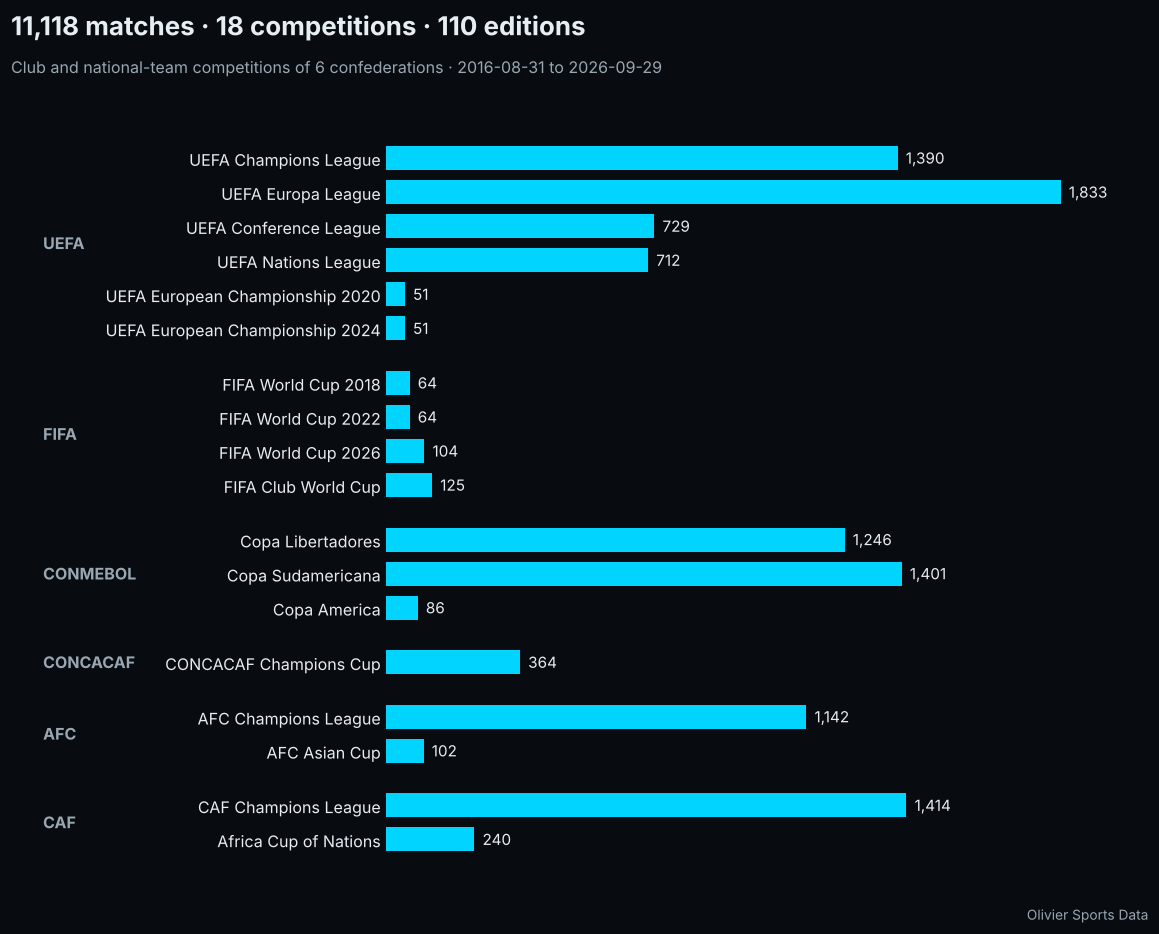

In [5]:
# matches per competition, grouped by confederation (also saved as a PNG: Output tab on Kaggle)
names = M.drop_duplicates("Competition_Code").set_index("Competition_Code")[["Confederation", "Competition"]]
label = {c: names.loc[c, "Competition"] + (f" {c[-4:]}" if c[-4:].isdigit() else "") for c in ORDER}
counts = M["Competition_Code"].value_counts().reindex(ORDER)
pos, y, blocks = [], 0.0, []
for i, c in enumerate(ORDER):
    if i and names.loc[c, "Confederation"] != names.loc[ORDER[i - 1], "Confederation"]:
        y += 0.6                                    # gap between two confederations
    pos.append(y)
    y += 1
fig, ax = plt.subplots(figsize=(11, 8.6))
fig.subplots_adjust(left=0.33, right=0.96, top=0.87, bottom=0.05)
ax.barh(pos, counts.values, height=0.7, color=CYAN, zorder=2)
ax.set_yticks(pos, [label[c] for c in ORDER], fontsize=10.5, color=FG)
ax.invert_yaxis()
for p, v in zip(pos, counts.values):
    ax.text(v + counts.max() * 0.012, p, f"{v:,}", va="center", fontsize=10, color=FG)
for conf in names["Confederation"].unique():
    ps = [p for p, c in zip(pos, ORDER) if names.loc[c, "Confederation"] == conf]
    ax.text(-0.45, (min(ps) + max(ps)) / 2, conf, transform=ax.get_yaxis_transform(),
            ha="left", va="center", fontsize=10.5, color=FG2, fontweight="bold")
ax.set_xlim(0, counts.max() * 1.13)
ax.xaxis.set_visible(False)
ax.grid(False)
ax.tick_params(axis="y", length=0)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
fig.text(0.02, 0.95, f"{len(M):,} matches · {M['Competition_Code'].nunique()} competitions · {len(editions)} editions",
         fontsize=17, fontweight="bold", color=FG)
fig.text(0.02, 0.91, f"Club and national-team competitions of 6 confederations · "
         f"{M['Kickoff_UTC'].min()[:10]} to {M['Kickoff_UTC'].max()[:10]}", fontsize=10.5, color=FG2)
fig.text(0.96, 0.015, "Olivier Sports Data", ha="right", fontsize=9, color=FG2)
fig.savefig("matches_per_competition.png", dpi=200, facecolor=BG)
plt.show()

## 4 · Opening and closing prices

One row per match. For each book and market: the first and the last valid pre-match quote, each with the time
it was recorded. The listing says a closing price is never an in-play price, so every closing time must sit
strictly before the scheduled kickoff.

In [6]:
head = pd.read_csv(os.path.join(ROOT, "Intl_Opening_Closing_Odds.csv"), nrows=0).columns
OC = pd.read_csv(os.path.join(ROOT, "Intl_Opening_Closing_Odds.csv"),
                 dtype={c: str for c in head if c.endswith(("_Open_Time", "_Close_Time")) or c in ("Match_ID", "Edition")})
check("one Opening_Closing row per match, same Match_IDs as Matches",
      len(OC) == len(M) and set(OC["Match_ID"]) == set(M["Match_ID"]))
kick = OC["Kickoff_Epoch"].astype("int64")
late, inverted, n_close = 0, 0, 0
for c in [c for c in OC.columns if c.endswith("_Close_Time")]:
    close = epoch(OC[c]); opened = epoch(OC[c.replace("_Close_", "_Open_")])
    n_close += close.notna().sum()
    late += (close >= kick).sum()
    inverted += (opened > close).sum()
check(f"all {n_close:,} closing times are before the scheduled kickoff", late == 0, f"{late} after")
check("opening time <= closing time everywhere", inverted == 0, f"{inverted} inverted")

cov = {b: int(OC[f"{b}_FT_1X2_Close_Time"].notna().sum()) for b in BOOKS}
check("matches with a FT 1X2 close, per book, as listed", cov == CLAIMS["ft_1x2_close_per_book"],
      " · ".join(f"{b} {n:,}" for b, n in cov.items()))

PASS  one Opening_Closing row per match, same Match_IDs as Matches


PASS  all 126,243 closing times are before the scheduled kickoff   [0 after]
PASS  opening time <= closing time everywhere   [0 inverted]
PASS  matches with a FT 1X2 close, per book, as listed   [Bet365 10,786 · Pinnacle 8,243 · Unibet 9,757 · Betfair 2,491 · Betsson 4,218]


### Coverage by competition — share of matches with a FT 1X2 closing price

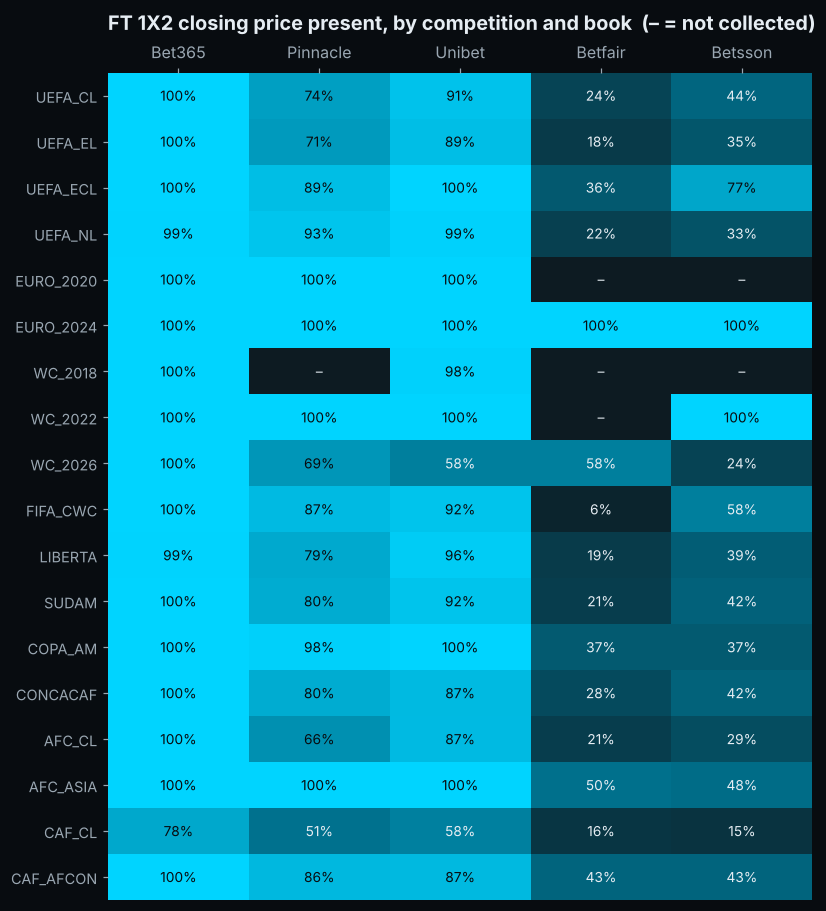

In [7]:
share = pd.DataFrame({b: OC.groupby("Competition_Code")[f"{b}_FT_1X2_Close_Time"].apply(lambda s: s.notna().mean())
                      for b in BOOKS}).reindex(ORDER)
cmap = LinearSegmentedColormap.from_list("cyan", ["#0d1b22", "#00708c", CYAN])
fig, ax = plt.subplots(figsize=(7.6, 8.4))
ax.imshow(share.values, aspect="auto", cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(BOOKS)), BOOKS)
ax.xaxis.tick_top()
ax.set_yticks(range(len(ORDER)), ORDER, fontsize=9.5)
ax.grid(False)
for i, c in enumerate(ORDER):
    for j, b in enumerate(BOOKS):
        v = share.loc[c, b]
        ax.text(j, i, "–" if v == 0 else f"{v:.0%}", ha="center", va="center", fontsize=9,
                color="#080c10" if v > 0.6 else FG)
ax.set_title("FT 1X2 closing price present, by competition and book  (– = not collected)", pad=28)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

### How close to kickoff is a "closing" price?

A closing quote is the last pre-match price the book published. Books update at different rhythms, so each one
gets its own closing time. Below: median and interquartile range of the gap to kickoff, FT 1X2.

PASS  median closing gap per book, as listed   [Pinnacle 3 min · Betfair 5 min · Betsson 7 min · Bet365 23 min · Unibet 48 min]


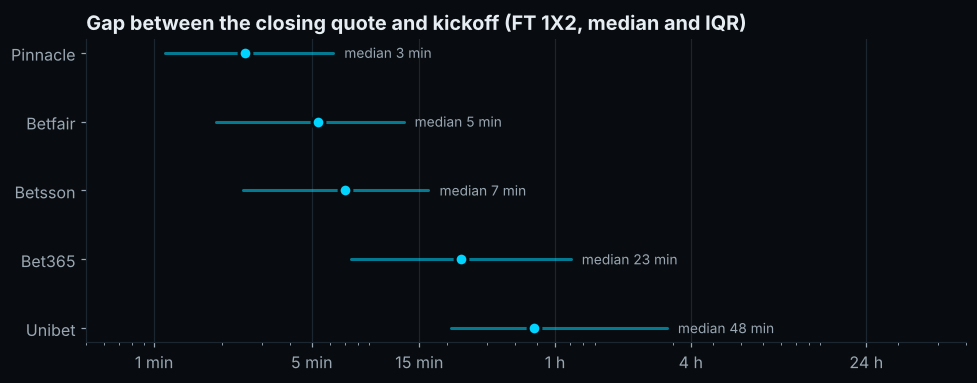

In [8]:
def upper_median(v):
    v = np.sort(np.asarray(v)); return v[len(v) // 2]

def readable(s):
    return f"{s / 3600:.1f} h" if s >= 5400 else f"{s / 60:.0f} min"

gaps = {}
for b in BOOKS:
    g = (kick - epoch(OC[f"{b}_FT_1X2_Close_Time"])).dropna().to_numpy()
    gaps[b] = g
got = {b: readable(upper_median(g)) for b, g in gaps.items()}
check("median closing gap per book, as listed", all(got[b] == CLAIMS["median_close_gap"][b] for b in BOOKS),
      " · ".join(f"{b} {got[b]}" for b in sorted(got, key=lambda b: upper_median(gaps[b]))))

books = sorted(BOOKS, key=lambda b: upper_median(gaps[b]), reverse=True)
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, b in enumerate(books):
    q1, q2, q3 = np.percentile(gaps[b] / 60, [25, 50, 75])
    ax.plot([q1, q3], [i, i], color=CYAN, linewidth=2, solid_capstyle="round", alpha=0.55)
    ax.scatter([q2], [i], s=70, color=CYAN, zorder=3, edgecolor=BG, linewidth=2)
    ax.text(q3 * 1.12, i, f"median {readable(upper_median(gaps[b]))}", va="center", fontsize=9, color=FG2)
ax.set_xscale("log")
ax.set_xticks([1, 5, 15, 60, 240, 1440], ["1 min", "5 min", "15 min", "1 h", "4 h", "24 h"])
ax.set_yticks(range(len(books)), books)
ax.set_xlim(0.5, 4000)
ax.grid(axis="y", visible=False)
ax.set_title("Gap between the closing quote and kickoff (FT 1X2, median and IQR)")
plt.tight_layout(); plt.show()

### Are these real market prices?

A real closing line is better informed than the opening one: its implied probabilities should predict results
better. Probabilities are de-margined proportionally; lower log-loss is better. Compare open and close **within a
book** — books cover different sets of matches, so the rows are not comparable with each other.

In [9]:
y = OC["Result_90"].map({"H": 0, "D": 1, "A": 2}).to_numpy()
rows = []
for b in BOOKS:
    cols = lambda k: [f"{b}_FT_1X2_{k}_{s}" for s in ("Home", "Draw", "Away")]
    o, c = OC[cols("Open")].to_numpy(float), OC[cols("Close")].to_numpy(float)
    ok = ~np.isnan(o).any(1) & ~np.isnan(c).any(1)
    def logloss(x):
        p = 1 / x[ok]; p = p / p.sum(1, keepdims=True)
        return -np.log(p[np.arange(ok.sum()), y[ok]]).mean()
    rows.append((b, ok.sum(), logloss(o), logloss(c), (1 / o[ok]).sum(1).mean() - 1, (1 / c[ok]).sum(1).mean() - 1))
LL = pd.DataFrame(rows, columns=["Book", "Matches", "LogLoss open", "LogLoss close", "Margin open", "Margin close"]).set_index("Book")
check("closing beats opening on log-loss, for every book", (LL["LogLoss close"] < LL["LogLoss open"]).all())
LL.style.format({"Matches": "{:,}", "LogLoss open": "{:.4f}", "LogLoss close": "{:.4f}",
                 "Margin open": "{:.2%}", "Margin close": "{:.2%}"})

PASS  closing beats opening on log-loss, for every book


,Matches,LogLoss open,LogLoss close,Margin open,Margin close
Book,,,,,
Bet365,"10,786",0.9392,0.9232,7.83%,6.20%
Pinnacle,"8,243",0.9405,0.9295,6.32%,4.29%
Unibet,"9,757",0.9384,0.9304,7.05%,6.36%
Betfair,"2,491",0.9293,0.9140,8.19%,10.46%
Betsson,"4,218",0.9252,0.9179,5.67%,5.67%


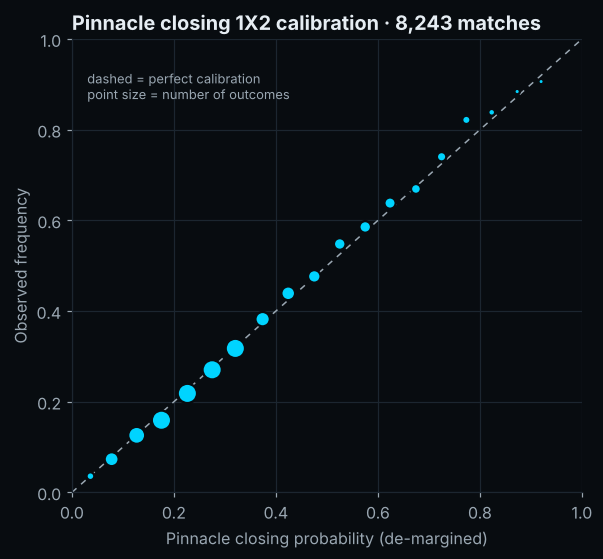

In [10]:
# Pinnacle closing 1X2: predicted probability vs observed frequency (all three outcomes pooled)
cols = [f"Pinnacle_FT_1X2_Close_{s}" for s in ("Home", "Draw", "Away")]
x = OC[cols].to_numpy(float); ok = ~np.isnan(x).any(1)
p = 1 / x[ok]; p = p / p.sum(1, keepdims=True)
hit = np.zeros_like(p); hit[np.arange(ok.sum()), y[ok]] = 1
cal = pd.DataFrame({"p": p.ravel(), "hit": hit.ravel()})
cal["bin"] = pd.cut(cal["p"], np.arange(0, 1.0001, 0.05))
cb = cal.groupby("bin", observed=True).agg(p=("p", "mean"), freq=("hit", "mean"), n=("hit", "size"))
cb = cb[cb["n"] >= 50]
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=FG2, linewidth=1, linestyle=(0, (4, 4)))
ax.scatter(cb["p"], cb["freq"], s=np.clip(cb["n"] / 15, 12, 160), color=CYAN, edgecolor=BG, linewidth=1.5, zorder=3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Pinnacle closing probability (de-margined)"); ax.set_ylabel("Observed frequency")
ax.set_title(f"Pinnacle closing 1X2 calibration · {ok.sum():,} matches")
ax.text(0.03, 0.93, "dashed = perfect calibration\npoint size = number of outcomes", fontsize=8.5, color=FG2, va="top")
plt.tight_layout(); plt.show()

## 5 · 29 million timestamped quotes

One pass over the 18 odds files, a few columns at a time. Checked on every row: a **pre-match** quote carries no
score and was recorded before the scheduled kickoff.

In [11]:
kick_by_id = pd.Series(M["Kickoff_Epoch"].to_numpy("int64"), index=M["Match_ID"].astype("int64"))
comp_by_id = pd.Series(M["Competition_Code"].to_numpy(), index=M["Match_ID"].astype("int64"))
use = ["Match_ID", "Book", "Phase", "Epoch", "Score_Home", "Suspended"]

def read(path, cols):
    try:
        d = pd.read_csv(path, usecols=cols, engine="pyarrow")   # fast, multi-threaded
    except Exception:
        d = pd.read_csv(path, usecols=cols)
    for c in d.columns:   # the pyarrow reader turns ISO times into datetimes: show them as written in the file
        if pd.api.types.is_datetime64_any_dtype(d[c]):
            d[c] = d[c].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
    return d

t0 = time.time()
by_book_phase, by_book_comp = [], []
pre_scored = pre_late = inplay_scored = n_rows = 0
off_manifest = []
for f in FILES["odds"]:
    d = read(f, use)
    n_rows += len(d)
    if len(d) != ROWS.get(stem(f)):
        off_manifest.append(stem(f))
    pre = d["Phase"] == "Pre-match"
    pre_scored += (pre & d["Score_Home"].notna()).sum()
    pre_late += (pre & (d["Epoch"].to_numpy() >= kick_by_id.reindex(d["Match_ID"]).to_numpy())).sum()
    inplay_scored += (~pre & d["Score_Home"].notna()).sum()
    by_book_phase.append(d.groupby(["Book", "Phase"]).size())
    by_book_comp.append(d.groupby([d["Book"], comp_by_id.reindex(d["Match_ID"]).to_numpy()]).size())
    print(f"{os.path.basename(f):45} {len(d):>12,} quotes   {time.time() - t0:5.0f} s")
    del d

bp = pd.concat(by_book_phase).groupby(level=[0, 1]).sum().unstack(fill_value=0)
phase = bp.sum()
check(f"{CLAIMS['quotes']:,} quotes, every file equal to the MANIFEST", n_rows == CLAIMS["quotes"] and not off_manifest,
      f"{n_rows:,}" + (f", off: {', '.join(off_manifest)}" if off_manifest else ""))
check("in-play / pre-match split as listed",
      phase.get("In-play", 0) == CLAIMS["in_play"] and phase.get("Pre-match", 0) == CLAIMS["pre_match"],
      f"{phase.get('In-play', 0):,} in-play · {phase.get('Pre-match', 0):,} pre-match")
check("quotes per book as listed", {b: int(n) for b, n in bp.sum(axis=1).items()} == CLAIMS["quotes_per_book"])
check("no pre-match quote carries a score", pre_scored == 0, f"{pre_scored}")
check("every pre-match quote is before the scheduled kickoff", pre_late == 0, f"{pre_late}")
print(f"in-play quotes with the score attached: {inplay_scored / phase.get('In-play', 1):.1%}")
bp.assign(Total=bp.sum(axis=1)).reindex(BOOKS).style.format("{:,}")

Intl_Odds_Timestamped_AFC_ASIA.csv.gz              461,171 quotes       2 s


Intl_Odds_Timestamped_AFC_CL.csv.gz              2,553,281 quotes      10 s


Intl_Odds_Timestamped_CAF_AFCON.csv.gz             771,426 quotes      11 s


Intl_Odds_Timestamped_CAF_CL.csv.gz              1,299,680 quotes      12 s


Intl_Odds_Timestamped_CONCACAF.csv.gz            1,022,176 quotes      13 s


...

Intl_Odds_Timestamped_UEFA_EL.csv.gz             5,047,844 quotes      39 s


Intl_Odds_Timestamped_UEFA_NL.csv.gz             2,216,065 quotes      41 s
Intl_Odds_Timestamped_WC_2018.csv.gz               164,531 quotes      41 s


Intl_Odds_Timestamped_WC_2022.csv.gz               213,629 quotes      41 s


Intl_Odds_Timestamped_WC_2026.csv.gz               237,772 quotes      41 s
PASS  28,943,376 quotes, every file equal to the MANIFEST   [28,943,376]
PASS  in-play / pre-match split as listed   [21,777,262 in-play · 7,166,114 pre-match]
PASS  quotes per book as listed
PASS  no pre-match quote carries a score   [0]
PASS  every pre-match quote is before the scheduled kickoff   [0]
in-play quotes with the score attached: 95.3%


Phase,In-play,Pre-match,Total
Book,,,
Bet365,"18,426,905","2,521,220","20,948,125"
Pinnacle,"114,163","1,487,628","1,601,791"
Unibet,"1,689,820","223,818","1,913,638"
Betfair,"1,189,679","2,530,071","3,719,750"
Betsson,"356,695","403,377","760,072"


Quotes per match, all markets, by competition: how often each book updated its prices.

In [12]:
bc = pd.concat(by_book_comp).groupby(level=[0, 1]).sum().unstack(level=0, fill_value=0).reindex(index=ORDER, columns=BOOKS)
matches_per_comp = M.groupby("Competition_Code").size()
(bc.div(matches_per_comp, axis=0)).round(0).astype(int).rename_axis("Quotes per match").style.format("{:,}")

Book,Bet365,Pinnacle,Unibet,Betfair,Betsson
Quotes per match,,,,,
AFC_ASIA,"2,225",175,202,"1,844",74
AFC_CL,"1,722",113,152,214,35
CAF_AFCON,"1,875",192,205,875,67
CAF_CL,751,27,58,67,15
CONCACAF,"2,075",83,172,428,50
COPA_AM,"2,732",253,240,"2,406",98
EURO_2020,"2,629",471,227,0,0
EURO_2024,"3,637",215,238,408,268
FIFA_CWC,"2,651",250,239,162,51


### 37 more bookmakers: dated snapshots

`Bookmaker_Snapshots` holds the first price the source kept for each other bookmaker (`Open`) and its latest
snapshot that is still pre-match (`Last_Pre_Match`). A dated snapshot, not a closing price: the minutes before
kickoff are given on every row.

In [13]:
ids = set(M["Match_ID"].astype("int64"))
parts, off = [], []
for f in FILES["snapshots"]:
    d = read(f, ["Match_ID", "Book", "Market", "Snapshot", "Minutes_Before_Kickoff"])
    if len(d) != ROWS.get(stem(f)):
        off.append(stem(f))
    parts.append(d)
S = pd.concat(parts, ignore_index=True); del parts
check(f"{CLAIMS['snapshots']:,} snapshot rows, all joined to a match", len(S) == CLAIMS["snapshots"] and S["Match_ID"].isin(ids).all()
      and not off, f"{len(S):,}" + (f", off the MANIFEST: {', '.join(off)}" if off else ""))
check(f"{CLAIMS['snapshot_books']} bookmakers, none of the 5 main books",
      S["Book"].nunique() == CLAIMS["snapshot_books"] and not set(S["Book"]) & set(BOOKS + ["Betfair (Sportsbook)"]),
      f"{S['Book'].nunique()} books")
check("every snapshot is pre-match (Minutes_Before_Kickoff >= 0)", (S["Minutes_Before_Kickoff"] >= 0).all())
last = S[S["Snapshot"] == "Last_Pre_Match"]
print(f"{S['Match_ID'].nunique():,} matches, {S.groupby('Match_ID')['Book'].nunique().mean():.1f} bookmakers per match on average")
(last.groupby("Market")["Minutes_Before_Kickoff"]
     .agg(rows="size", median_minutes_before_kickoff="median",
          within_60_min=lambda s: f"{(s <= 60).mean():.0%}", over_24_h=lambda s: f"{(s > 1440).mean():.0%}"))

PASS  661,507 snapshot rows, all joined to a match   [661,507]


PASS  37 bookmakers, none of the 5 main books   [37 books]
PASS  every snapshot is pre-match (Minutes_Before_Kickoff >= 0)
10,486 matches, 14.8 bookmakers per match on average


,rows,median_minutes_before_kickoff,within_60_min,over_24_h
Market,,,,
FT_1X2,152223,74.0,48%,29%
FT_Asian_Handicap,71845,291.0,45%,36%
FT_Total_Goals,106759,100.0,47%,31%


### Lineups, events, minute-by-minute stats

Rows counted from the files themselves, and every row must join a match of `Intl_Matches` on `Match_ID`.

In [14]:
for folder, claim in (("lineups", "lineups"), ("events", "events"), ("minute_stats", "minute_stats")):
    n, orphans, off = 0, 0, []
    for f in FILES[folder]:
        d = read(f, ["Match_ID"])
        n += len(d)
        orphans += (~d["Match_ID"].isin(ids)).sum()
        if len(d) != ROWS.get(stem(f)):
            off.append(stem(f))
    check(f"{CLAIMS[claim]:,} {folder.replace('_', ' ')} rows, all joined to a match", n == CLAIMS[claim] and orphans == 0 and not off,
          f"{n:,} rows, {orphans} without a match" + (f", off the MANIFEST: {', '.join(off)}" if off else ""))

PASS  401,511 lineups rows, all joined to a match   [401,511 rows, 0 without a match]
PASS  365,177 events rows, all joined to a match   [365,177 rows, 0 without a match]


PASS  3,037,116 minute stats rows, all joined to a match   [3,037,116 rows, 0 without a match]


## 6 · One match, quote by quote

The table shown in the listing: Argentina 2-2 France, FIFA World Cup final, 18 December 2022, Bet365 full-time
1X2 in play (the 90-minute market). Recomputed here from `Intl_Odds_Timestamped_WC_2022.csv.gz`, then drawn as
implied probabilities, with the goals of the events table on top. The events table counts the minute being
played (a goal at 35:20 is 36'), Bet365's clock counts the minutes elapsed (35), so a price jump usually sits one
minute left of its dotted line. Early in this match Bet365's clock ran about five minutes behind: the 23rd-minute
penalty shows at its 18th minute. Clocks are delivered as the bookmaker sent them, never adjusted.

In [15]:
MID = 6025486
row = M[M["Match_ID"] == str(MID)].iloc[0]
check("the Matches row: 2-2 after 90 minutes, 3-3 after extra time, 4-2 on penalties, neutral venue",
      (row["Home_Goals_90"], row["Away_Goals_90"], row["Home_Goals_AET"], row["Away_Goals_AET"],
       row["Home_Penalties"], row["Away_Penalties"], row["Neutral_Venue"]) == (2, 2, 3, 3, 4, 2, 1))
cols = ["Match_ID", "Book", "Market", "Phase", "Timestamp_UTC", "Epoch", "Minute",
        "Score_Home", "Score_Away", "Price_Home", "Price_Draw", "Price_Away", "Suspended"]
wc = read(next(f for f in FILES["odds"] if stem(f).endswith("_WC_2022")), cols)
one = wc[wc["Match_ID"] == MID]
del wc
t = one[(one["Book"] == "Bet365") & (one["Market"] == "FT_1X2") & (one["Phase"] == "In-play")].sort_values("Epoch", kind="stable")
t = t.reset_index(drop=True)
check(f"{CLAIMS['example_in_play_bet365_1x2']} in-play Bet365 1X2 quotes on this match",
      len(t) == CLAIMS["example_in_play_bet365_1x2"], f"{len(t)}")

# the listing's rule: around each score change, the quote before and the quote at the change
keep, last = [], None
for i, sc in enumerate(zip(t["Score_Home"].fillna(-1), t["Score_Away"].fillna(-1))):
    if sc != last:
        keep += [k for k in (i - 1, i) if k >= 0 and k not in keep]
        last = sc
show = (t.loc[keep[:16], ["Timestamp_UTC", "Minute", "Score_Home", "Score_Away", "Price_Home", "Price_Draw", "Price_Away", "Suspended"]]
          .astype({"Minute": "Int64", "Score_Home": "Int64", "Score_Away": "Int64"}))
show

PASS  the Matches row: 2-2 after 90 minutes, 3-3 after extra time, 4-2 on penalties, neutral venue


PASS  144 in-play Bet365 1X2 quotes on this match   [144]


,Timestamp_UTC,Minute,Score_Home,Score_Away,Price_Home,Price_Draw,Price_Away,Suspended
0,2022-12-18T15:05:38Z,<NA>,0,0,2.625,3.100,2.875,0
16,2022-12-18T15:22:32Z,17,0,0,NaN,NaN,NaN,1
17,2022-12-18T15:23:15Z,18,1,0,1.500,3.750,8.000,0
24,2022-12-18T15:35:33Z,35,1,0,NaN,NaN,NaN,1
25,2022-12-18T15:35:57Z,35,2,0,1.083,9.500,29.000,0
82,2022-12-18T16:42:10Z,79,2,0,NaN,NaN,NaN,1
83,2022-12-18T16:42:22Z,79,2,1,1.181,5.000,41.000,0
89,2022-12-18T16:43:50Z,81,2,1,NaN,NaN,NaN,1
90,2022-12-18T16:43:58Z,81,2,2,3.600,1.533,8.000,0


 Minute  Added_Time Team_Side   Player
   23.0         NaN      Home    Messi
   36.0         NaN      Home di Maria
   80.0         NaN      Away   Mbappe
   81.0         NaN      Away   Mbappe
  109.0         NaN      Home    Messi
  118.0         NaN      Away   Mbappe


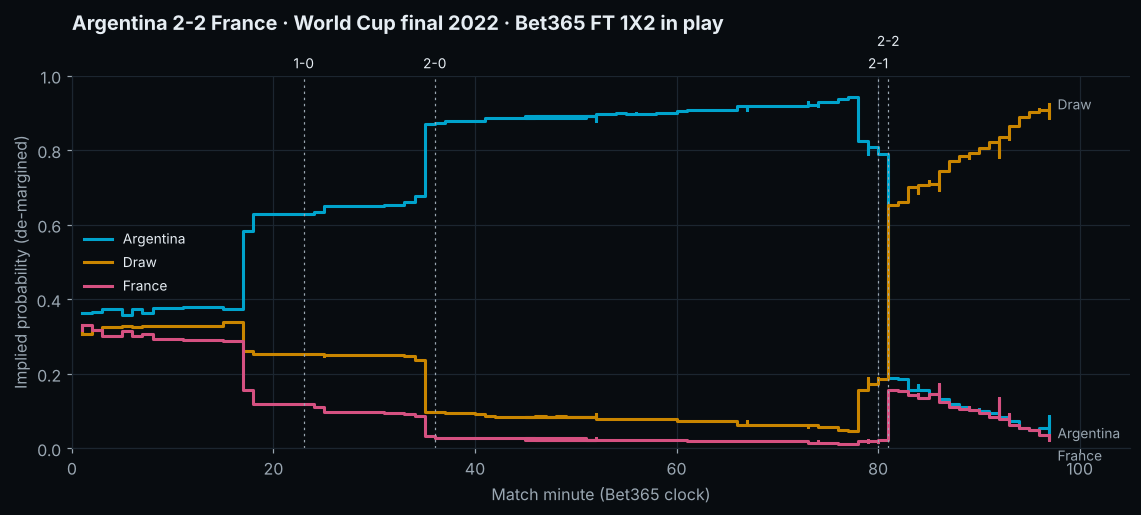

In [16]:
ev = read(next(f for f in FILES["events"] if stem(f).endswith("_WC_2022")),
          ["Match_ID", "Minute", "Added_Time", "Event_Type", "Team_Side", "Player"])
goals = ev[(ev["Match_ID"] == MID) & (ev["Event_Type"] == "Goal")].sort_values(["Minute", "Added_Time"], na_position="first")
print(goals[["Minute", "Added_Time", "Team_Side", "Player"]].to_string(index=False))
goals90 = goals[goals["Minute"] <= 90]          # the 1X2 market settles after 90 minutes: extra-time goals are not drawn

live = t[t["Suspended"] == 0].copy()
inv = 1 / live[["Price_Home", "Price_Draw", "Price_Away"]]
prob = inv.div(inv.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(10.5, 4.8))
x = live["Minute"]
names = {"Price_Home": "Argentina", "Price_Draw": "Draw", "Price_Away": "France"}
for col, side in zip(prob.columns, ["Home", "Draw", "Away"]):
    ax.plot(x, prob[col], color=HDA[side], linewidth=2, label=names[col], drawstyle="steps-post")
ends = sorted(((prob[col].iloc[-1], col) for col in prob.columns), reverse=True)
y_lab = []
for v, col in ends:                                   # end labels kept at least 0.06 apart
    y_lab.append(min(v, y_lab[-1] - 0.06) if y_lab else v)
    ax.text(x.iloc[-1] + 0.8, y_lab[-1], names[col], color=FG2, fontsize=9, va="center")
score_h = score_a = 0
previous, level = -99, 0
for _, g in goals90.iterrows():
    m = g["Minute"] + (0 if pd.isna(g["Added_Time"]) else g["Added_Time"])
    score_h += g["Team_Side"] == "Home"; score_a += g["Team_Side"] == "Away"
    level = 1 - level if m - previous < 5 else 0          # stagger labels of goals close together
    previous = m
    ax.axvline(m, color=FG2, linewidth=0.8, linestyle=(0, (2, 3)))
    ax.text(m, 1.02 + 0.06 * level, f"{score_h}-{score_a}", ha="center", fontsize=9, color=FG,
            transform=ax.get_xaxis_transform())
ax.set_ylim(0, 1); ax.set_xlim(0, max(97, x.max() + 8))
ax.set_xlabel("Match minute (Bet365 clock)"); ax.set_ylabel("Implied probability (de-margined)")
ax.set_title("Argentina 2-2 France · World Cup final 2022 · Bet365 FT 1X2 in play", pad=30)
ax.legend(loc="center left", fontsize=9)
plt.tight_layout(); plt.show()

## 7 · Nothing a spreadsheet can reinterpret

Formations are digits (4231 = 4-2-3-1), timestamps carry the T and the Z, editions read 2016/17 or 2019, and no
text cell starts with a character a spreadsheet would read as a formula or turn into a date.

In [17]:
iso = re.compile(r"^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}Z$")
risky = re.compile(r"^([=+@\-]|\d{1,2}[-/]\d{1,2}([-/]\d{2,4})?$|\d{1,2}:\d{2}(:\d{2})?$)")
form = pd.concat([M["Home_Formation"], M["Away_Formation"]]).dropna()
check("formations are digits that add up to 10 players",
      form.str.fullmatch(r"\d{3,5}").all() and form.map(lambda s: sum(map(int, s)) == 10).all(),
      f"{len(form):,} formations, e.g. {form.value_counts().index[0]}")
check("editions read 2016/17 or 2019", M["Edition"].str.fullmatch(r"\d{4}(/\d{2})?").all(),
      ", ".join(sorted(M["Edition"].unique())[:4]) + "...")
times = pd.concat([M["Kickoff_UTC"]] + [OC[c].dropna() for c in OC.columns if c.endswith(("_Open_Time", "_Close_Time"))])
check("every timestamp is ISO 8601 with T and Z", times.map(lambda s: bool(iso.match(s))).all(), f"{len(times):,} cells")
TS = pd.read_csv(os.path.join(ROOT, "Intl_Team_Stats.csv"), dtype=str)
is_text = lambda s: s.dtype == object or isinstance(s.dtype, pd.StringDtype)
text_cells = pd.concat([df[c].dropna().astype(str) for df in (M, OC, TS) for c in df.columns if is_text(df[c])
                        and not c.endswith(("_Open_Time", "_Close_Time", "_UTC"))])
bad = text_cells[text_cells.map(lambda s: bool(risky.match(s)))]
check("no text cell a spreadsheet would rewrite (Matches, Opening_Closing, Team_Stats)", bad.empty,
      f"{len(text_cells):,} text cells" + (f", e.g. {bad.iloc[0]!r}" if len(bad) else ""))
check(f"{CLAIMS['team_stats']:,} team-stat rows, two per match", len(TS) == CLAIMS["team_stats"] == 2 * len(M))

PASS  formations are digits that add up to 10 players   [13,850 formations, e.g. 4231]
PASS  editions read 2016/17 or 2019   [2016, 2016/17, 2017, 2017/18...]
PASS  every timestamp is ISO 8601 with T and Z   [263,604 cells]


PASS  no text cell a spreadsheet would rewrite (Matches, Opening_Closing, Team_Stats)   [892,611 text cells]
PASS  22,236 team-stat rows, two per match


## 8 · Summary

In [18]:
summary = pd.DataFrame(RESULTS, columns=["Claim", "Pass", "Detail"])
print(f"{summary['Pass'].sum()} / {len(summary)} claims verified")
summary.assign(Result=summary["Pass"].map({True: "PASS", False: "FAIL"}))[["Result", "Claim", "Detail"]].style.hide(axis="index")

35 / 35 claims verified


Result,Claim,Detail
PASS,all 97 files present,
PASS,every SHA-256 matches the MANIFEST,
PASS,"11,118 matches","11,118"
PASS,Match_ID is unique,
PASS,"9,644 club matches + 1,474 national-team matches","9,644 + 1,474"
PASS,"18 competitions, 6 confederations, 110 editions",18 / 6 / 110
PASS,"matches per competition, as listed",
PASS,"first kickoff on 31 Aug 2016, last before 1 Oct 2026",2016-08-31T20:00:00Z to 2026-09-29T18:45:00Z
PASS,"extra time on 206 matches, shoot-outs on 270, 1,190 at neutral venues","206 / 270 / 1,190"
PASS,Result_90 agrees with the 90-minute score on every match,


---

Everything above ran on the files a buyer downloads. The README in the ZIP holds the full column dictionary,
the editions and stages of every competition, the coverage tables, the 8 removed source events with their
evidence, and every known limitation.

👉 ⚽ **[→ Get the full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/hethzg?utm_source=github&utm_medium=notebook&utm_campaign=intl_premium&utm_content=notebook_bottom)** 👈

A question before buying: contact@oliviersportsdata.com

*Olivier Sports Data — From Chicken Area 🐔*